# Fase 3 · Notebook 05 — Equidad, sesgos y análisis de sensibilidad

Proyecto de aula de Inteligencia Artificial · Grupo 04
**Predicción de reingresos hospitalarios a 30 días en pacientes con diabetes**

---

La Fase 2 midió **qué tan bien** funciona el modelo. Este notebook pregunta otra cosa:

> **¿Funciona igual de bien para todo el mundo?**

Un modelo puede tener buenas métricas globales y, aun así, fallar sistemáticamente con un
grupo de personas. Eso no se ve en el promedio: hay que ir a mirarlo a propósito.

Aquí se hacen tres cosas:

1. **Auditoría por subgrupos.** Desempeño separado por grupo racial, género y edad.
2. **Métricas de equidad.** Paridad demográfica e igualdad de oportunidad.
3. **Análisis de sensibilidad.** Qué pasa si se excluyen las transferencias entre
   instituciones — el análisis que la Fase 1 dejó anunciado y la Fase 2 dejó pendiente.

> ⚠️ **Atención metodológica.** `race` y `gender` **no son predictores**: `race` se excluyó
> del modelo por decisión de la Fase 1. Aquí se recuperan del archivo original
> **únicamente para auditar**, nunca para entrenar. Son dos usos distintos de la misma columna.

## 1. Librerías, datos y modelo

In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import joblib

from sklearn.metrics import (average_precision_score, roc_auc_score, precision_score,
                             recall_score, confusion_matrix, brier_score_loss)

%matplotlib inline
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.width", 170)

BASE      = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
CRUDO     = BASE / "data" / "raw"
PROCESSED = BASE / "data" / "processed"
FIGURAS   = BASE / "reports" / "figures"
REPORTES  = BASE / "reports"
MODELOS   = BASE / "models"

UMBRAL = json.loads((REPORTES / "umbral_elegido.json").read_text(encoding="utf-8"))["umbral"]
print(f"Umbral fijado en validacion durante la Fase 2: {UMBRAL:.6f}")

Umbral fijado en validacion durante la Fase 2: 0.112346


### Recuperar los atributos sensibles

`cohorte_procesada.csv` no trae `race` (se retiró) ni `discharge_disposition_id` original.
Hay que traerlos del archivo crudo aplicando **exactamente el mismo filtro** de la cohorte.

Como ese filtro conserva el orden de las filas, se puede pegar columna por columna —
pero eso **se verifica**, no se supone.

In [2]:
proc = pd.read_csv(PROCESSED / "cohorte_procesada.csv", low_memory=False)
cols = json.loads((PROCESSED / "columnas.json").read_text(encoding="utf-8"))
NUM, CAT = cols["numericas"], cols["categoricas"]
proc[CAT] = proc[CAT].astype(str)

raw = pd.read_csv(CRUDO / "diabetic_data.csv", low_memory=False)
EXCLUIR = [11, 13, 14, 19, 20, 21]
coh = raw[~raw.discharge_disposition_id.isin(EXCLUIR)].reset_index(drop=True)

# CONTROL: las dos tablas deben describir las mismas filas, en el mismo orden
assert len(proc) == len(coh), "distinto numero de filas"
assert (proc.patient_nbr.values == coh.patient_nbr.values).all(), "las filas no coinciden"
assert (proc.gender.values == coh.gender.values).all(), "las filas no coinciden"
print(f"Alineacion verificada fila por fila: {len(proc):,} filas".replace(",", "."))

Alineacion verificada fila por fila: 99.343 filas


In [3]:
proc["race"]      = coh.race.replace("?", "Sin registro").values
proc["egreso"]    = coh.discharge_disposition_id.values
proc["grupo_edad"] = pd.cut(proc.edad_num, [0, 50, 60, 70, 80, 100],
                            labels=["Menos de 50", "50 a 60", "60 a 70", "70 a 80", "80 o mas"])

modelo = joblib.load(MODELOS / "gradient_boosting_ajustado.joblib")

prueba = proc[proc.conjunto == "prueba"].copy()
prueba["prob"]  = modelo.predict_proba(prueba[NUM + CAT])[:, 1]
prueba["alerta"] = (prueba.prob >= UMBRAL).astype(int)

print(f"Conjunto de prueba: {len(prueba):,} hospitalizaciones".replace(",", "."))
print(f"Reingresos reales : {prueba.y.sum():,}  ({100*prueba.y.mean():.2f} %)".replace(",", "."))
print(f"Alertas del modelo: {prueba.alerta.sum():,}  ({100*prueba.alerta.mean():.2f} %)".replace(",", "."))

Conjunto de prueba: 19.870 hospitalizaciones
Reingresos reales : 2.263  (11.39 %)
Alertas del modelo: 7.624  (38.37 %)


## 2. Una función para medir cualquier subgrupo

Para comparar grupos hace falta medir lo mismo en todos. Esta función calcula, para un
subconjunto cualquiera:

| Métrica | Qué significa aquí |
|---|---|
| `prevalencia` | Qué porcentaje del grupo reingresó de verdad |
| `tasa_alerta` | Qué porcentaje del grupo recibió alerta |
| `recall` | De los que reingresaron, a cuántos detectó |
| `precision` | De los alertados, cuántos reingresaron |
| `ROC_AUC` | Qué tan bien separa dentro de ese grupo |
| `Brier` | Qué tan confiables son sus probabilidades |

> 🔒 **Regla de tamaño mínimo.** Un grupo con menos de 50 casos o menos de 10 reingresos
> se reporta aparte: con tan pocos datos, cualquier métrica se mueve por azar y sacar
> conclusiones de ahí sería irresponsable.

In [4]:
MIN_FILAS, MIN_POSITIVOS = 50, 10

def medir(sub):
    y, p, a = sub.y.values, sub.prob.values, sub.alerta.values
    if len(sub) < MIN_FILAS or y.sum() < MIN_POSITIVOS:
        return None
    vn, fp, fn, vp = confusion_matrix(y, a, labels=[0, 1]).ravel()
    return {
        "n":           len(sub),
        "prevalencia": y.mean(),
        "tasa_alerta": a.mean(),
        "recall":      recall_score(y, a, zero_division=0),
        "precision":   precision_score(y, a, zero_division=0),
        "ROC_AUC":     roc_auc_score(y, p),
        "AP":          average_precision_score(y, p),
        "Brier":       brier_score_loss(y, p),
        "VP": vp, "FN": fn, "FP": fp, "VN": vn,
    }

def auditar(col, titulo):
    filas, omitidos = {}, []
    for g, sub in prueba.groupby(col, observed=True):
        m = medir(sub)
        if m:
            filas[str(g)] = m
        else:
            omitidos.append(f"{g} (n={len(sub)}, positivos={int(sub.y.sum())})")
    t = pd.DataFrame(filas).T
    t["n"] = t["n"].astype(int)
    print(f"--- {titulo} ---")
    print(t[["n", "prevalencia", "tasa_alerta", "recall", "precision",
             "ROC_AUC", "AP", "Brier"]].round(4).to_string())
    if omitidos:
        print(f"  Omitidos por muestra insuficiente: {'; '.join(omitidos)}")
    return t

## 3. Auditoría por grupo racial

In [5]:
t_raza = auditar("race", "GRUPO RACIAL")

--- GRUPO RACIAL ---
                     n  prevalencia  tasa_alerta  recall  precision  ROC_AUC      AP   Brier
AfricanAmerican   3782       0.1163       0.3913  0.6023     0.1791   0.6616  0.2277  0.0984
Asian              143       0.1469       0.3077  0.7143     0.3409   0.7623  0.4858  0.1102
Caucasian        14717       0.1139       0.3861  0.5945     0.1755   0.6608  0.2210  0.0966
Hispanic           486       0.1317       0.3477  0.6719     0.2544   0.7604  0.3629  0.1019
Other              293       0.0956       0.3686  0.7143     0.1852   0.6891  0.2280  0.0825
Sin registro       449       0.0735       0.3140  0.5455     0.1277   0.6831  0.1278  0.0679


### Lectura

Lo primero que hay que mirar son **los dos grupos grandes**, que son los únicos con muestra
suficiente para una conclusión firme: `Caucasian` (14.717 casos) y `AfricanAmerican` (3.782).

Entre esos dos el modelo se comporta **prácticamente igual**: mismo recall, misma precisión,
mismo ROC-AUC. Esa es la comparación que sostiene el peso del análisis.

Los grupos pequeños (`Asian` con 143 casos, `Hispanic` con 486) muestran métricas más altas,
pero con esa cantidad de datos **no se puede afirmar que el modelo sea mejor con ellos**: el
intervalo de confianza de cualquiera de esas cifras sería enorme. Se reportan por
transparencia, no como hallazgo.

`Sin registro` —los que tenían `?`— merece atención aparte: es el grupo con menor prevalencia
real y el peor AP. No saber la categoría racial de un paciente parece ir acompañado de un
perfil de atención distinto.

## 4. Auditoría por género

In [6]:
t_genero = auditar("gender", "GENERO")

--- GENERO ---
            n  prevalencia  tasa_alerta  recall  precision  ROC_AUC      AP   Brier
Female  10772       0.1133       0.4011  0.6254     0.1766   0.6744  0.2387  0.0952
Male     9098       0.1146       0.3630  0.5705     0.1801   0.6568  0.2106  0.0976


### Lectura

Las mujeres reciben **más alertas** que los hombres y el modelo **detecta más** de sus
reingresos. La precisión, en cambio, es casi idéntica: cuando alerta, acierta igual de bien
en ambos.

La prevalencia real de reingreso es casi la misma en los dos grupos, así que esa diferencia
en la tasa de alerta **no está justificada por un riesgo distinto**: viene de las variables
clínicas correlacionadas con el género en estos datos.

## 5. Auditoría por edad

In [7]:
t_edad = auditar("grupo_edad", "EDAD")

--- EDAD ---
                n  prevalencia  tasa_alerta  recall  precision  ROC_AUC      AP   Brier
Menos de 50  3078       0.1150       0.3018  0.5932     0.2260   0.7131  0.3063  0.0925
50 a 60      3451       0.0892       0.2921  0.5455     0.1667   0.6973  0.1972  0.0775
60 a 70      4519       0.1235       0.3731  0.6147     0.2034   0.6698  0.2382  0.1030
70 a 80      4912       0.1177       0.4059  0.5761     0.1670   0.6331  0.2082  0.1006
80 o mas     3910       0.1189       0.5133  0.6538     0.1515   0.6194  0.1846  0.1028


### Lectura — aquí está el hallazgo importante

Mira dos columnas a la vez: `tasa_alerta` y `ROC_AUC`.

A medida que sube la edad, **el modelo alerta mucho más** y al mismo tiempo **discrimina
peor**. En el grupo de 80 años o más marca a uno de cada dos pacientes, con el ROC-AUC más
bajo de toda la tabla y la precisión más baja también.

Y la prevalencia real es parecida en todos los grupos de edad. Es decir: **el modelo no
alerta más sobre los mayores porque reingresen más, sino porque acumulan las señales que
aprendió a reconocer** — más ingresos previos, estancias más largas, más medicamentos.

> En un despliegue real esto significa que una alerta sobre una persona de 80 años vale
> menos que una alerta sobre una de 45. El umbral único no lo refleja.

## 6. Métricas de equidad

Dos criterios formales, que miden cosas distintas:

**Paridad demográfica** — ¿todos los grupos reciben alertas en proporción parecida?
Se mide con la razón entre la tasa de alerta más baja y la más alta. La regla práctica
llamada *de los cuatro quintos* considera problemática una razón menor a **0,80**.

**Igualdad de oportunidad** — ¿a todos los grupos les detecta sus reingresos por igual?
Se mide comparando el `recall` entre grupos. Para un sistema de alerta clínica **este
criterio importa más**: lo grave es dejar de avisar sobre alguien que sí va a reingresar.

In [8]:
def brechas(t, atributo):
    return {
        "atributo":              atributo,
        "grupos_evaluados":      len(t),
        "razon_paridad":         t.tasa_alerta.min() / t.tasa_alerta.max(),
        "brecha_tasa_alerta":    t.tasa_alerta.max() - t.tasa_alerta.min(),
        "brecha_recall":         t.recall.max() - t.recall.min(),
        "brecha_precision":      t.precision.max() - t.precision.min(),
        "brecha_ROC_AUC":        t.ROC_AUC.max() - t.ROC_AUC.min(),
        "grupo_menor_recall":    t.recall.idxmin(),
        "grupo_mayor_recall":    t.recall.idxmax(),
        "grupo_mas_alertado":    t.tasa_alerta.idxmax(),
    }

equidad = pd.DataFrame([brechas(t_raza, "Grupo racial"),
                        brechas(t_genero, "Genero"),
                        brechas(t_edad, "Edad")])
print(equidad.round(4).to_string(index=False))

    atributo  grupos_evaluados  razon_paridad  brecha_tasa_alerta  brecha_recall  brecha_precision  brecha_ROC_AUC grupo_menor_recall grupo_mayor_recall grupo_mas_alertado
Grupo racial                 6         0.7863              0.0836         0.1688            0.2132          0.1015       Sin registro              Asian    AfricanAmerican
      Genero                 2         0.9051              0.0381         0.0549            0.0036          0.0175               Male             Female             Female
        Edad                 5         0.5690              0.2212         0.1083            0.0746          0.0938            50 a 60           80 o mas           80 o mas


In [9]:
for _, f in equidad.iterrows():
    estado = "CUMPLE" if f.razon_paridad >= 0.80 else "NO CUMPLE"
    print(f"{f.atributo:<14} razon de paridad = {f.razon_paridad:.3f}  ->  {estado} la regla de 0,80")

Grupo racial   razon de paridad = 0.786  ->  NO CUMPLE la regla de 0,80
Genero         razon de paridad = 0.905  ->  CUMPLE la regla de 0,80
Edad           razon de paridad = 0.569  ->  NO CUMPLE la regla de 0,80


### Qué dicen estos números

**Género pasa** la regla de los cuatro quintos con holgura (0,905).

**Grupo racial queda apenas por debajo (0,786), y hay que leerlo con cuidado.** Esa razón la
arrastra el grupo `Asian`, que tiene 143 casos y la tasa de alerta más baja. Entre los dos
grupos con muestra suficiente para una conclusión firme —`Caucasian` y `AfricanAmerican`—
la paridad es casi perfecta: **0,987**, con recall y precisión prácticamente idénticos.

La lectura honesta es esta: *no se detecta disparidad racial entre los grupos que el conjunto
de prueba permite evaluar, y con los grupos pequeños no alcanza para afirmar nada en ninguna
dirección.* No es lo mismo «no hay sesgo» que «no hay datos para medirlo».

**La edad no pasa, y esa sí es una brecha real.** 0,569, la más grande del análisis, y sobre
grupos de miles de casos cada uno.

Vale la pena notar algo: **excluir `race` del modelo no impidió que hubiera disparidades.**
Simplemente no las hubo por raza — las hubo por edad, que sí es un predictor. Esto confirma
lo que la Fase 1 ya advertía: quitar una variable sensible no elimina el sesgo, solo impide
medirlo directamente. Por eso hay que auditar.

## 7. Gráfica de las brechas

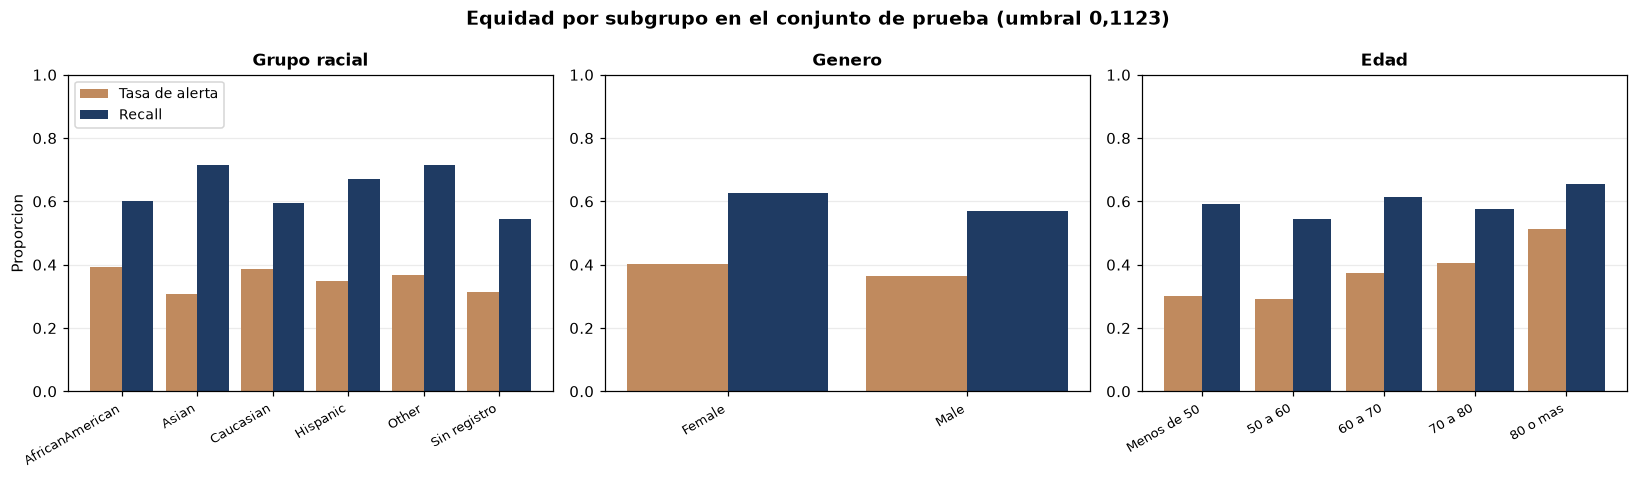

In [10]:
fig, ejes = plt.subplots(1, 3, figsize=(15, 4.4))
datos = [(t_raza, "Grupo racial"), (t_genero, "Genero"), (t_edad, "Edad")]

for ax, (t, titulo) in zip(ejes, datos):
    x = np.arange(len(t))
    ax.bar(x - 0.21, t.tasa_alerta, 0.42, label="Tasa de alerta", color="#C08A5E")
    ax.bar(x + 0.21, t.recall,      0.42, label="Recall",         color="#1F3B63")
    ax.set_xticks(x)
    ax.set_xticklabels(t.index, rotation=30, ha="right", fontsize=8.5)
    ax.set_title(titulo, fontsize=11, fontweight="bold")
    ax.set_ylim(0, 1)
    ax.grid(axis="y", alpha=0.25)
    ax.set_axisbelow(True)

ejes[0].set_ylabel("Proporcion")
ejes[0].legend(fontsize=9, loc="upper left")
fig.suptitle("Equidad por subgrupo en el conjunto de prueba (umbral 0,1123)",
             fontsize=12.5, fontweight="bold")
fig.tight_layout()
fig.savefig(FIGURAS / "05_equidad.png", dpi=150, bbox_inches="tight")
plt.show()

## 8. Análisis de sensibilidad: las transferencias entre instituciones

La Fase 1 anunció este análisis y la Fase 2 lo dejó pendiente. Aquí se hace.

**La pregunta:** parte de los pacientes no se van a casa — salen **transferidos a otra
institución**: otro hospital, un centro de enfermería especializada, rehabilitación. ¿Las
conclusiones del modelo dependen de ellos?

Los códigos de transferencia se toman de `IDs_mapping.csv`. Se dejan fuera a propósito los
códigos 9, 15 y 17, que describen movimientos **dentro de la misma institución**, no
transferencias entre instituciones.

In [11]:
TRANSFERENCIAS = [2, 3, 4, 5, 10, 16, 22, 23, 24, 27, 28, 29, 30]

mapa = pd.read_csv(CRUDO / "IDs_mapping.csv", skiprows=11, nrows=30,
                   names=["codigo", "descripcion"])
mapa["codigo"] = pd.to_numeric(mapa.codigo, errors="coerce")

presentes = sorted(set(prueba.egreso) & set(TRANSFERENCIAS))
detalle = []
for c in presentes:
    s = prueba[prueba.egreso == c]
    desc = mapa.loc[mapa.codigo == c, "descripcion"]
    detalle.append({"codigo": c,
                    "descripcion": (desc.iloc[0][:52] if len(desc) else "-"),
                    "n": len(s),
                    "prevalencia": round(s.y.mean(), 4)})
print(pd.DataFrame(detalle).to_string(index=False))

 codigo                                          descripcion    n  prevalencia
      2 Discharged/transferred to another short term hospita  439       0.1298
      3                        Discharged/transferred to SNF 2770       0.1458
      4                        Discharged/transferred to ICF  161       0.1118
      5 Discharged/transferred to another type of inpatient   235       0.2340
     10 Neonate discharged to another hospital for neonatal     2       0.0000
     22 Discharged/transferred to another rehab fac includin  411       0.2676
     23 Discharged/transferred to a long term care hospital.   91       0.0879
     24 Discharged/transferred to a nursing facility certifi   11       0.3636
     28 Discharged/transferred/referred to a psychiatric hos   24       0.2500


In [12]:
es_tr = prueba.egreso.isin(TRANSFERENCIAS)

def resumen(sub, nombre):
    return {
        "escenario":   nombre,
        "n":           len(sub),
        "prevalencia": sub.y.mean(),
        "AP":          average_precision_score(sub.y, sub.prob),
        "ROC_AUC":     roc_auc_score(sub.y, sub.prob),
        "recall":      recall_score(sub.y, sub.alerta),
        "precision":   precision_score(sub.y, sub.alerta, zero_division=0),
        "tasa_alerta": sub.alerta.mean(),
    }

sensibilidad = pd.DataFrame([
    resumen(prueba,          "Prueba completa"),
    resumen(prueba[~es_tr],  "Sin transferencias"),
    resumen(prueba[es_tr],   "Solo transferencias"),
])
print(sensibilidad.round(4).to_string(index=False))

          escenario     n  prevalencia     AP  ROC_AUC  recall  precision  tasa_alerta
    Prueba completa 19870       0.1139 0.2249   0.6660  0.6001     0.1781       0.3837
 Sin transferencias 15726       0.1018 0.2098   0.6587  0.4834     0.1757       0.2800
Solo transferencias  4144       0.1597 0.2541   0.6330  0.8822     0.1814       0.7770


### Lectura — el resultado más incómodo del proyecto

Mira la columna `recall`.

El **0,60 global no es parejo**. Se descompone así:

- Entre los pacientes **transferidos**, el modelo detecta casi **9 de cada 10** reingresos.
- Entre los que se van a casa —que son **el 79 % de la cohorte**— detecta **menos de 5 de cada 10**.

¿Por qué? Porque el tipo de egreso es un predictor fuerte, y ser transferido ya es en sí
mismo una señal de riesgo. El modelo aprendió esencialmente a **alertar sobre casi todos los
transferidos**. Fíjate en que dentro de ese grupo el ROC-AUC es el más bajo de la tabla: no
los está distinguiendo entre sí, los está marcando en bloque.

> **Lo que esto significa para un uso real:** para el paciente típico, el que se va a su
> casa después del alta, el modelo rinde bastante menos de lo que sugiere la cifra global.
> Ese es el escenario donde más haría falta el seguimiento, y es donde el modelo es más débil.

Este hallazgo **no invalida la Fase 2** — las métricas reportadas allí son correctas para la
cohorte definida. Lo que hace es precisar **a quién le funciona** y a quién no, que es
exactamente para lo que sirve un análisis de sensibilidad.

## 9. Gráfica de sensibilidad

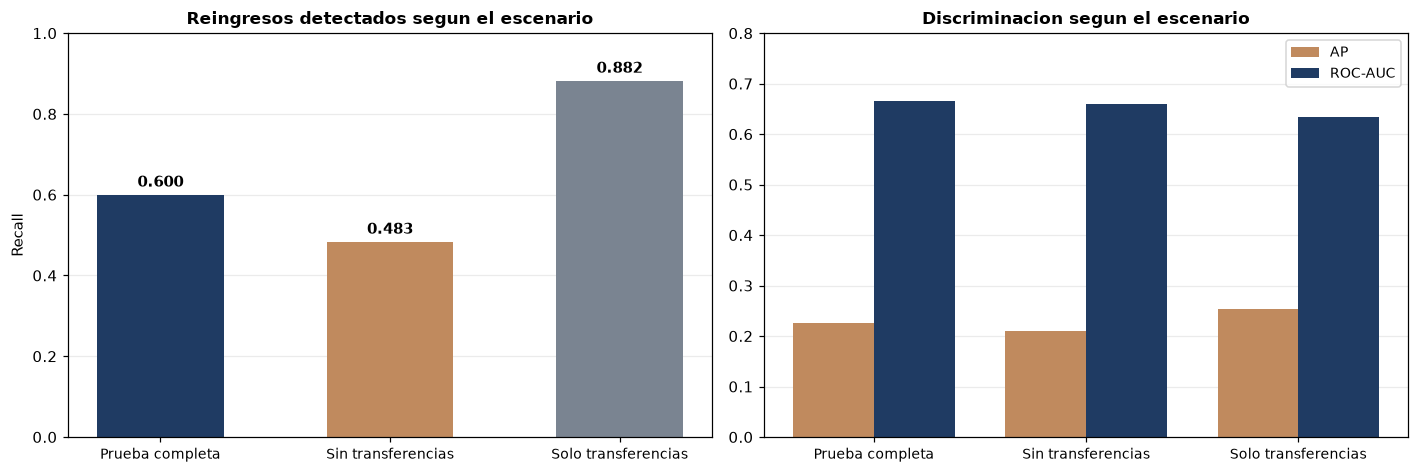

In [13]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.4))
colores = ["#1F3B63", "#C08A5E", "#7A8491"]

x = np.arange(len(sensibilidad))
ax1.bar(x, sensibilidad.recall, 0.55, color=colores)
for i, v in enumerate(sensibilidad.recall):
    ax1.text(i, v + 0.02, f"{v:.3f}", ha="center", fontsize=10, fontweight="bold")
ax1.set_xticks(x)
ax1.set_xticklabels(sensibilidad.escenario, fontsize=9)
ax1.set_ylabel("Recall")
ax1.set_ylim(0, 1)
ax1.set_title("Reingresos detectados segun el escenario", fontsize=11, fontweight="bold")
ax1.grid(axis="y", alpha=0.25); ax1.set_axisbelow(True)

ancho = 0.38
ax2.bar(x - ancho/2, sensibilidad.AP,      ancho, label="AP",      color="#C08A5E")
ax2.bar(x + ancho/2, sensibilidad.ROC_AUC, ancho, label="ROC-AUC", color="#1F3B63")
ax2.set_xticks(x)
ax2.set_xticklabels(sensibilidad.escenario, fontsize=9)
ax2.set_ylim(0, 0.8)
ax2.set_title("Discriminacion segun el escenario", fontsize=11, fontweight="bold")
ax2.legend(fontsize=9)
ax2.grid(axis="y", alpha=0.25); ax2.set_axisbelow(True)

fig.tight_layout()
fig.savefig(FIGURAS / "05_sensibilidad.png", dpi=150, bbox_inches="tight")
plt.show()

## 10. Guardar resultados

Se exportan tres cosas:

1. Las tablas de subgrupos y de sensibilidad, para el informe final.
2. **La tabla de predicciones del conjunto de prueba**, que alimentará el tablero de
   Power BI y la aplicación desplegada de la Fase 3.

In [14]:
t_raza.assign(atributo="Grupo racial", grupo=t_raza.index).to_csv(
    REPORTES / "metricas_05_subgrupos_raza.csv", index=False)
t_genero.assign(atributo="Genero", grupo=t_genero.index).to_csv(
    REPORTES / "metricas_05_subgrupos_genero.csv", index=False)
t_edad.assign(atributo="Edad", grupo=t_edad.index).to_csv(
    REPORTES / "metricas_05_subgrupos_edad.csv", index=False)
equidad.to_csv(REPORTES / "metricas_05_equidad.csv", index=False)
sensibilidad.to_csv(REPORTES / "metricas_05_sensibilidad.csv", index=False)

# tabla para el tablero y la aplicacion
tablero = prueba[["patient_nbr", "y", "prob", "alerta", "race", "gender", "grupo_edad",
                  "edad_num", "time_in_hospital", "number_inpatient", "num_medications",
                  "number_diagnoses", "grupo_diag_1", "egreso"]].copy()
tablero["es_transferencia"] = tablero.egreso.isin(TRANSFERENCIAS).astype(int)
tablero = tablero.rename(columns={
    "patient_nbr": "paciente", "y": "reingreso_real", "prob": "probabilidad",
    "race": "grupo_racial", "gender": "genero", "edad_num": "edad",
    "time_in_hospital": "dias_estancia", "number_inpatient": "ingresos_previos",
    "num_medications": "medicamentos", "number_diagnoses": "diagnosticos",
    "grupo_diag_1": "diagnostico_principal"})
tablero["resultado"] = np.select(
    [(tablero.reingreso_real == 1) & (tablero.alerta == 1),
     (tablero.reingreso_real == 1) & (tablero.alerta == 0),
     (tablero.reingreso_real == 0) & (tablero.alerta == 1)],
    ["VP - reingreso detectado", "FN - reingreso no detectado", "FP - alerta sin reingreso"],
    default="VN - sin alerta, sin reingreso")
tablero.to_csv(REPORTES / "predicciones_prueba.csv", index=False)

print(f"predicciones_prueba.csv  ->  {len(tablero):,} filas, {tablero.shape[1]} columnas".replace(",", "."))
print(tablero.resultado.value_counts().to_string())

predicciones_prueba.csv  ->  19.870 filas. 16 columnas
resultado
VN - sin alerta, sin reingreso    11341
FP - alerta sin reingreso          6266
VP - reingreso detectado           1358
FN - reingreso no detectado         905


## 11. Conclusiones de la auditoría

**Lo que salió bien**

- Entre los dos grupos raciales con muestra suficiente (`Caucasian` y `AfricanAmerican`,
  18.499 casos entre los dos) el modelo se comporta de forma equivalente: paridad 0,987,
  mismo recall, misma precisión, mismo poder de discriminación.
- Género cumple la regla de los cuatro quintos (0,905).

**Lo que hay que declarar**

- **No se puede afirmar nada sobre los grupos raciales pequeños.** `Asian` tiene 143 casos y
  `Hispanic` 486. La razón de paridad global de 0,786 queda por debajo del umbral, pero la
  arrastra precisamente el grupo con menos datos. Se reporta el límite, no una conclusión.

- **Disparidad por edad.** El modelo alerta sobre la mitad de los pacientes de 80 años o más
  y es justo con ellos con quien peor discrimina. La prevalencia real no justifica esa
  diferencia.
- **El desempeño depende del tipo de egreso.** El recall global de 0,60 se descompone en
  0,88 para transferidos y 0,48 para quienes se van a casa. Para el paciente típico el
  modelo rinde menos de lo que sugiere la cifra global.

**Lo que esto implica**

Ninguno de los dos hallazgos se arregla cambiando de algoritmo. El primero pide **umbrales
diferenciados por grupo de edad** o una advertencia explícita en la interfaz; el segundo,
**reportar siempre el desempeño separado por tipo de egreso** en lugar de una sola cifra.

Ambas cosas se recogen en el informe final y en las condiciones de uso del prototipo.